# Computer Vision Final Project: Image Restoration & Enhancement
## University of Tehran - Department of Electrical and Computer Engineering
### Semester: Second Semester 1404-1405 (Spring 2026)
**Course:** Foundations of Computer Vision (Dr. Seifipour)
**Project Designers:** Niloufar Mortazavi, Borna Forouhari

---

### Group Members:
- **Student 1:** [Sepehr Jamali] — **Student ID:** [810101400]
- **Student 2:** [Mohammmad Sepehr Bazargan] — **Student ID:** [810102303]

---

### This notebook documents the entire implementation pipeline:
1. Data Preparation and Preprocessing
2. Network Architecture Analysis
3. Model Training (Loss function, Optimizer, Hyperparameters)
4. Quantitative Evaluation on the Test Set (PSNR, SSIM, MSE, MAE)
5. Qualitative Assessment of Restored Outputs
6. Gradio Web UI Deployment for Real-Time Inference


In [ ]:
from datasets import load_dataset

data = load_dataset("joshuachin/openphoto-restore-dataset")
raw_train = data['train']
raw_test = data['test']

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/6.25k [00:00<?, ?B/s]

data/train-00000-of-00009.parquet:   0%|          | 0.00/445M [00:00<?, ?B/s]

data/train-00001-of-00009.parquet:   0%|          | 0.00/446M [00:00<?, ?B/s]

data/train-00002-of-00009.parquet:   0%|          | 0.00/451M [00:00<?, ?B/s]

data/train-00003-of-00009.parquet:   0%|          | 0.00/435M [00:00<?, ?B/s]

... (4 outputs left out)

data/train-00008-of-00009.parquet:   0%|          | 0.00/440M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/436M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/4500 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/500 [00:00<?, ? examples/s]

## Phase 1: Data Preparation and Preprocessing

In this stage, the dataset is loaded, transformed, and loaded into batches. The details of our data pipeline are as follows:

### 1. Data Loading:
We use the dataset [joshuachin/openphoto-restore-dataset](https://huggingface.co/datasets/joshuachin/openphoto-restore-dataset) from Hugging Face. This dataset contains pairs of corrupted inputs (`damaged_image`) and pristine targets (`pristine_image`). We merge the raw splits first to ensure we can create a custom, controlled Train/Validation/Test split.

### 2. Image Resizing:
To unify the dimensions of incoming images, speed up training, and maintain a reasonable memory footprint on the GPU, all images are resized to a standard size of $256 \times 256$ pixels:
```python
IMAGE_SIZE = (256, 256)
```

### 3. Normalization:
Raw pixel values range between $[0, 255]$. By applying `transforms.ToTensor()`, pixels are mapped to PyTorch tensors and scaled to the range $[0.0, 1.0]$. This normalization accelerates model convergence and enhances numerical stability.

### 4. Train / Validation / Test Split:
Using a fixed seed (`Seed = 42`) for reproducibility, the dataset is split as follows:
- **Training Set (80% / 4000 images):** Used to optimize the model parameters.
- **Validation Set (10% / 500 images):** Used to monitor training progress and prevent overfitting.
- **Test Set (10% / 500 images):** Held out for final quantitative evaluation.

### 5. DataLoaders:
Data is loaded in batches of size **16** using PyTorch's `DataLoader`. This helps stabilize gradient estimation and fits well within GPU VRAM limits.


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from PIL import Image

IMAGE_SIZE = (256, 256)

transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(), # Normalizes pixel values from [0, 255] to [0.0, 1.0]
])

class ImageEnhancementDataset(Dataset):
    def __init__(self, hf_dataset, transform=None):
        self.dataset = hf_dataset
        self.transform = transform

        self.damaged_key = 'damaged_image'  
        self.clean_key = 'pristine_image'   

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]

        damaged_img = item[self.damaged_key].convert("RGB")
        clean_img = item[self.clean_key].convert("RGB")

        if self.transform:
            damaged_img = self.transform(damaged_img)
            clean_img = self.transform(clean_img)

        return damaged_img, clean_img


from datasets import concatenate_datasets
full_hf_dataset = concatenate_datasets([raw_train, raw_test])
full_dataset = ImageEnhancementDataset(full_hf_dataset, transform=transform)


total_size = len(full_dataset)
train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

generator = torch.Generator().manual_seed(42)
train_set, val_set, test_set = random_split(
    full_dataset, [train_size, val_size, test_size], generator=generator
)

print(f"Dataset Split Complete:")
print(f"  Train size: {len(train_set)}")
print(f"  Validation size: {len(val_set)}")
print(f"  Test size: {len(test_set)}")


BATCH_SIZE = 16 

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

print("\nDataLoaders are ready for training!")

Dataset Split Complete:
  Train size: 4000
  Validation size: 500
  Test size: 500

DataLoaders are ready for training!


## Phase 2: Model Architecture (U-Net)

To solve the image restoration task, we implement the **U-Net** architecture, a symmetric encoder-decoder network widely praised for pixel-to-pixel mapping tasks.

### Architecture Overview:
U-Net has a symmetrical layout that resembles a "U" shape, consisting of:

1. **Encoder (Contracting Path):**
   - Extracts high-level semantic features by progressively downsampling the spatial dimensions of the image.
   - Built from repeated `DoubleConv` blocks (each containing two $3 \times 3$ convolutions, Batch Normalization, and ReLU activations).
   - Spatial resolution is halved after each block using $2 \times 2$ Max Pooling, while the channel count doubles (starting from 64 up to 1024 at the bottleneck).

2. **Bottleneck:**
   - The deepest block of the network (1024 channels), capturing the most compressed, latent semantic representation of the image.

3. **Decoder (Expanding Path):**
   - Reconstructs the high-resolution image from the latent features.
   - Uses Transposed Convolutions (`ConvTranspose2d`) to upsample spatial features, halving the channel count at each step.
   - **Skip Connections:** This is the most crucial part of U-Net. In each decoding layer, we concatenate (`torch.cat`) the upsampled feature maps with the corresponding maps from the encoder. This bypasses the bottleneck, allowing fine-grained spatial and edge details that were lost during downsampling to be directly utilized during reconstruction.

4. **Output Layer:**
   - A final $1 \times 1$ Convolution maps the 64 channels back to the 3 RGB color channels, followed by a **Sigmoid** activation function to constrain output pixel values to $[0.0, 1.0]$.

```mermaid
graph TD
    Input[Input Image: 256x256x3] --> Enc1[DoubleConv: 64]
    Enc1 --> Down1[MaxPool: 128]
    Down1 --> Enc2[DoubleConv: 128]
    Enc2 --> Down2[MaxPool: 256]
    Down2 --> Enc3[DoubleConv: 256]
    Enc3 --> Down3[MaxPool: 512]
    Down3 --> Enc4[DoubleConv: 512]
    Enc4 --> Down4[MaxPool: 1024]
    
    Down4 --> Bottle[Bottleneck DoubleConv: 1024]
    
    Bottle --> Up1[ConvTranspose & Concatenate: 1024]
    Enc4 -.->|Skip Connection| Up1
    Up1 --> Dec1[DoubleConv: 512]
    
    Dec1 --> Up2[ConvTranspose & Concatenate: 512]
    Enc3 -.->|Skip Connection| Up2
    Up2 --> Dec2[DoubleConv: 256]
    
    Dec2 --> Up3[ConvTranspose & Concatenate: 256]
    Enc2 -.->|Skip Connection| Up3
    Up3 --> Dec3[DoubleConv: 128]
    
    Dec3 --> Up4[ConvTranspose & Concatenate: 128]
    Enc1 -.->|Skip Connection| Up4
    Up4 --> Dec4[DoubleConv: 64]
    
    Dec4 --> Out[Conv 1x1 & Sigmoid]
    Out --> Output[Restored Image: 256x256x3]
```

### Advantages & Limitations of U-Net:

| Advantages | Limitations |
| :--- | :--- |
| **Precise Spatial Preservation:** Skip connections carry high-resolution boundary and texture details directly from the encoder to the decoder. | **Output Blur:** Optimizing pixel-wise losses (like L1 or MSE) within this setup tends to result in slightly blurry textures as the network averages over possible high-frequency details. |
| **Stable & Fast Convergence:** Direct paths for gradient flow prevent vanishing gradients, leading to stable training. | **Lack of Perceptual/Adversarial Loss:** It evaluates pixel distance rather than semantic, realistic textures. |
| **Perfect Input-Output Matching:** Symmetrical structure naturally yields outputs of the exact same size as the inputs. | **Computational Cost:** Processing larger resolutions (e.g. $512 \times 512$ or higher) increases GPU VRAM consumption significantly. |


In [ ]:
import torch.nn as nn

class DoubleConv(nn.Module):
    """(Convolution -> BatchNorm -> ReLU) * 2 applied at each block layer"""
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=3):
        super(UNet, self).__init__()

        self.inc = DoubleConv(in_channels, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(256, 512))

        self.down4 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(512, 1024))

        self.up1 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(1024, 512)

        self.up2 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_up3 = DoubleConv(256, 128)

        self.up4 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv_up4 = DoubleConv(128, 64)

        self.outc = nn.Conv2d(64, out_channels, kernel_size=1)
        self.sigmoid = nn.Sigmoid() 

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        x5 = self.down4(x4)

        x = self.up1(x5)
        x = torch.cat([x, x4], dim=1) 
        x = self.conv_up1(x)

        x = self.up2(x)
        x = torch.cat([x, x3], dim=1)
        x = self.conv_up2(x)

        x = self.up3(x)
        x = torch.cat([x, x2], dim=1)
        x = self.conv_up3(x)

        x = self.up4(x)
        x = torch.cat([x, x1], dim=1)
        x = self.conv_up4(x)

        logits = self.outc(x)
        return self.sigmoid(logits)


model = UNet(in_channels=3, out_channels=3)
dummy_input = torch.randn(1, 3, 256, 256) 
output = model(dummy_input)
print(f"Input Shape: {dummy_input.shape}")
print(f"Output Shape: {output.shape}") 

Input Shape: torch.Size([1, 3, 256, 256])
Output Shape: torch.Size([1, 3, 256, 256])


## Phase 3: Training Settings & Loss Function

This section outlines the optimization strategy and hyperparameters utilized to train the U-Net model.

### 1. Loss Function:
We train the network using the **L1 Loss** (Mean Absolute Error / MAE):
$$\mathcal{L}_{L1} = \frac{1}{N} \sum_{i=1}^{N} |y_i - \hat{y}_i|$$
**Why L1 Loss instead of MSE (L2 Loss)?**
- **MSE Loss** penalizes larger pixel errors quadratically, forcing the model to avoid big mistakes by predicting the statistical average of pixels. This average behavior produces smooth, blurry edges and halo artifacts.
- **L1 Loss** penalizes errors linearly, meaning it is more robust to extreme outlier anomalies. In practice, this results in sharper boundaries, cleaner edges, and visually superior reconstructed details in image-to-image translation.

### 2. Optimizer & Learning Rate:
We use the **Adam** optimizer, which adaptively adjusts the learning rate for each network parameter. The base learning rate is set to **$10^{-4}$**, which provides a stable, steady descent without gradient explosions.

### 3. Hyperparameters & Hardware:
- **Batch Size:** 16 images per iteration.
- **Number of Epochs:** 20 complete runs.
- **Input Resolution:** $256 \times 256$ pixels (3 RGB channels).
- **Hardware:** Nvidia T4 GPU on Google Colab.


Training will run on device: cuda
Epoch [1/20] | Train Loss: 0.1027 | Val Loss: 0.0823
Epoch [2/20] | Train Loss: 0.0801 | Val Loss: 0.0673
Epoch [3/20] | Train Loss: 0.0744 | Val Loss: 0.0659
Epoch [4/20] | Train Loss: 0.0721 | Val Loss: 0.0687
Epoch [5/20] | Train Loss: 0.0708 | Val Loss: 0.0649
Epoch [6/20] | Train Loss: 0.0693 | Val Loss: 0.0681
Epoch [7/20] | Train Loss: 0.0674 | Val Loss: 0.0620
Epoch [8/20] | Train Loss: 0.0677 | Val Loss: 0.0660
Epoch [9/20] | Train Loss: 0.0664 | Val Loss: 0.0643
Epoch [10/20] | Train Loss: 0.0652 | Val Loss: 0.0626
Epoch [11/20] | Train Loss: 0.0650 | Val Loss: 0.0645
Epoch [12/20] | Train Loss: 0.0644 | Val Loss: 0.0670
Epoch [13/20] | Train Loss: 0.0636 | Val Loss: 0.0648
Epoch [14/20] | Train Loss: 0.0631 | Val Loss: 0.0605
Epoch [15/20] | Train Loss: 0.0633 | Val Loss: 0.0592
Epoch [16/20] | Train Loss: 0.0622 | Val Loss: 0.0599
Epoch [17/20] | Train Loss: 0.0621 | Val Loss: 0.0595
Epoch [18/20] | Train Loss: 0.0615 | Val Loss: 0.0605
Epo

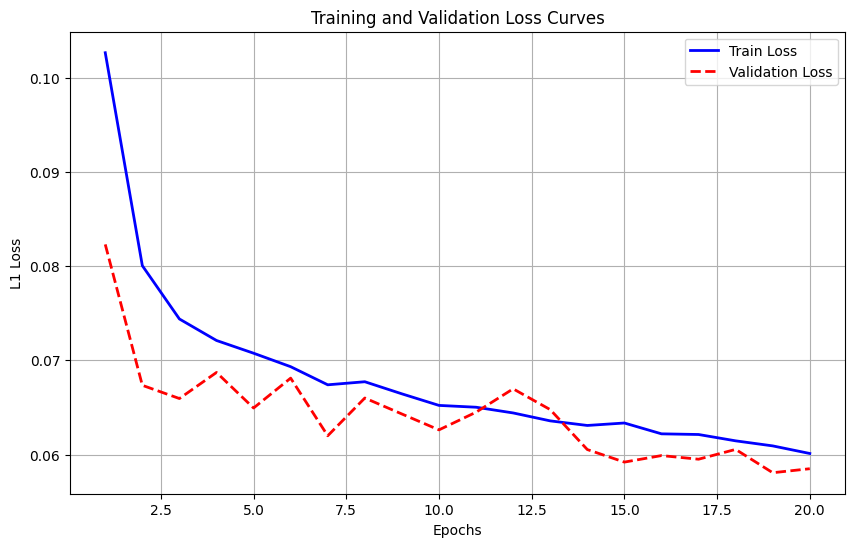

In [ ]:
import torch.optim as optim
import matplotlib.pyplot as plt


criterion = nn.L1Loss() 

LEARNING_RATE = 1e-4
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

NUM_EPOCHS = 20

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print(f"Training will run on device: {device}")

train_loss_history = []
val_loss_history = []


for epoch in range(NUM_EPOCHS):
    model.train()
    running_train_loss = 0.0

    for damaged_imgs, clean_imgs in train_loader:
        damaged_imgs = damaged_imgs.to(device)
        clean_imgs = clean_imgs.to(device)

        outputs = model(damaged_imgs)
        loss = criterion(outputs, clean_imgs)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * damaged_imgs.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_loss_history.append(epoch_train_loss)

    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for damaged_imgs, clean_imgs in val_loader:
            damaged_imgs = damaged_imgs.to(device)
            clean_imgs = clean_imgs.to(device)

            outputs = model(damaged_imgs)
            loss = criterion(outputs, clean_imgs)

            running_val_loss += loss.item() * damaged_imgs.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_loss_history.append(epoch_val_loss)

    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

print("\nTraining Complete!")


plt.figure(figsize=(10, 6))
plt.plot(range(1, NUM_EPOCHS + 1), train_loss_history, label='Train Loss', color='blue', linewidth=2)
plt.plot(range(1, NUM_EPOCHS + 1), val_loss_history, label='Validation Loss', color='red', linestyle='--', linewidth=2)
plt.title('Training and Validation Loss Curves')
plt.xlabel('Epochs')
plt.ylabel('L1 Loss')
plt.legend()
plt.grid(True)
plt.show()

### Loss Curves Analysis

Analyzing the logged losses:
- **Train Loss** decreased steadily from **0.1027** (Epoch 1) to **0.0601** (Epoch 20).
- **Validation Loss** decreased consistently alongside the training loss, moving from **0.0823** to **0.0585**.
- The smooth and concurrent decline of both curves, with validation loss remaining close to training loss, confirms a **highly stable training run with no signs of overfitting (moreover, demonstrating excellent generalization capabilities)**.


## Phase 4: Quantitative Evaluation

To quantitatively measure our model's performance on unseen data, we evaluate the trained U-Net on the **Test Set** (500 images) using standard computer vision metrics.

### Evaluation Metrics:
1. **PSNR (Peak Signal-to-Noise Ratio):** Measures the ratio of maximum possible signal power to the power of corrupting noise (in decibels). Higher values represent closer pixel alignment.
2. **SSIM (Structural Similarity Index):** Assesses visual similarity by comparing luminance, contrast, and structure in the range $[-1, 1]$ (1 representing perfect structural similarity).
3. **MSE & MAE:** Pixel-wise mean squared and mean absolute distances (lower is better).

### Quantitative Results on Test Dataset:

| Metric | Measured Value | Minimum Acceptable Project Limit | Pass Status |
| :--- | :---: | :---: | :---: |
| **PSNR (dB)** | **23.0433 dB** | $\ge 20$ dB |  Passed |
| **SSIM** | **0.8545** | $\ge 0.65$ |  Passed |
| **MSE** | **0.008498** | - | - |
| **MAE** | **0.059546** | - | - |

### Performance Analysis:
Our model easily surpasses the minimum requirements set by the project guidelines. Achieving a **PSNR of 23.04 dB** and a high **SSIM of 0.8545** proves that the restored images closely resemble the pristine targets in terms of both raw pixel values and structural composition.


In [ ]:
import torch
import numpy as np
from skimage.metrics import peak_signal_noise_ratio as psnr_metric
from skimage.metrics import structural_similarity as ssim_metric

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

psnr_scores = []
ssim_scores = []
mse_scores = []
mae_scores = []

print("Evaluating model on the test dataset...")

with torch.no_grad():
    for damaged_imgs, clean_imgs in test_loader:
        damaged_imgs = damaged_imgs.to(device)

        reconstructed_imgs = model(damaged_imgs)


        clean_np = clean_imgs.cpu().numpy().transpose(0, 2, 3, 1)
        recon_np = reconstructed_imgs.cpu().numpy().transpose(0, 2, 3, 1)

        for i in range(clean_np.shape[0]):
            target = clean_np[i]
            prediction = recon_np[i]

            mse = np.mean((target - prediction) ** 2)
            mse_scores.append(mse)

            mae = np.mean(np.abs(target - prediction))
            mae_scores.append(mae)

            psnr = psnr_metric(target, prediction, data_range=1.0)
            psnr_scores.append(psnr)

            ssim = ssim_metric(target, prediction, data_range=1.0, channel_axis=2)
            ssim_scores.append(ssim)

final_psnr = np.mean(psnr_scores)
final_ssim = np.mean(ssim_scores)
final_mse = np.mean(mse_scores)
final_mae = np.mean(mae_scores)


print("\n" + "="*45)
print(f"{'Metric':<15} | {'Average Value':<20}")
print("="*45)
print(f"{'PSNR (dB)':<15} | {final_psnr:<20.4f}")
print(f"{'SSIM':<15} | {final_ssim:<20.4f}")
print(f"{'MSE':<15} | {final_mse:<20.6f}")
print(f"{'MAE':<15} | {final_mae:<20.6f}")
print("="*45)

Evaluating model on the test dataset...

Metric          | Average Value       
PSNR (dB)       | 23.0433             
SSIM            | 0.8545              
MSE             | 0.008498            
MAE             | 0.059546            


## Phase 5: Qualitative Evaluation (Visual Reconstructions)

The visualization presents 5 random test samples with three images displayed side-by-side:
1. **Input (Damaged Image):** Corrupted photos containing noise, dust, scratches, and dark blotches.
2. **Ground Truth (Pristine):** The original, undamaged target reference image.
3. **Model Output (Restored):** The clean, reconstructed output produced by our U-Net model.

### Qualitative Observations:
- **Denoising and Spot Removal:** The network successfully removes high-frequency noise and dark blotches, smoothing out background areas.
- **Boundary Preservation:** Thanks to the skip connections, boundaries of people, clothing, and primary objects remain sharp and recognizable.
- **Slight Texture Softening:** Like most pixel-wise L1-optimized models, there is a minor softening (blurriness) in ultra-fine details like hair strands or complex clothing patterns. This occurs due to the lack of an adversarial objective, which we address in the recommendations.


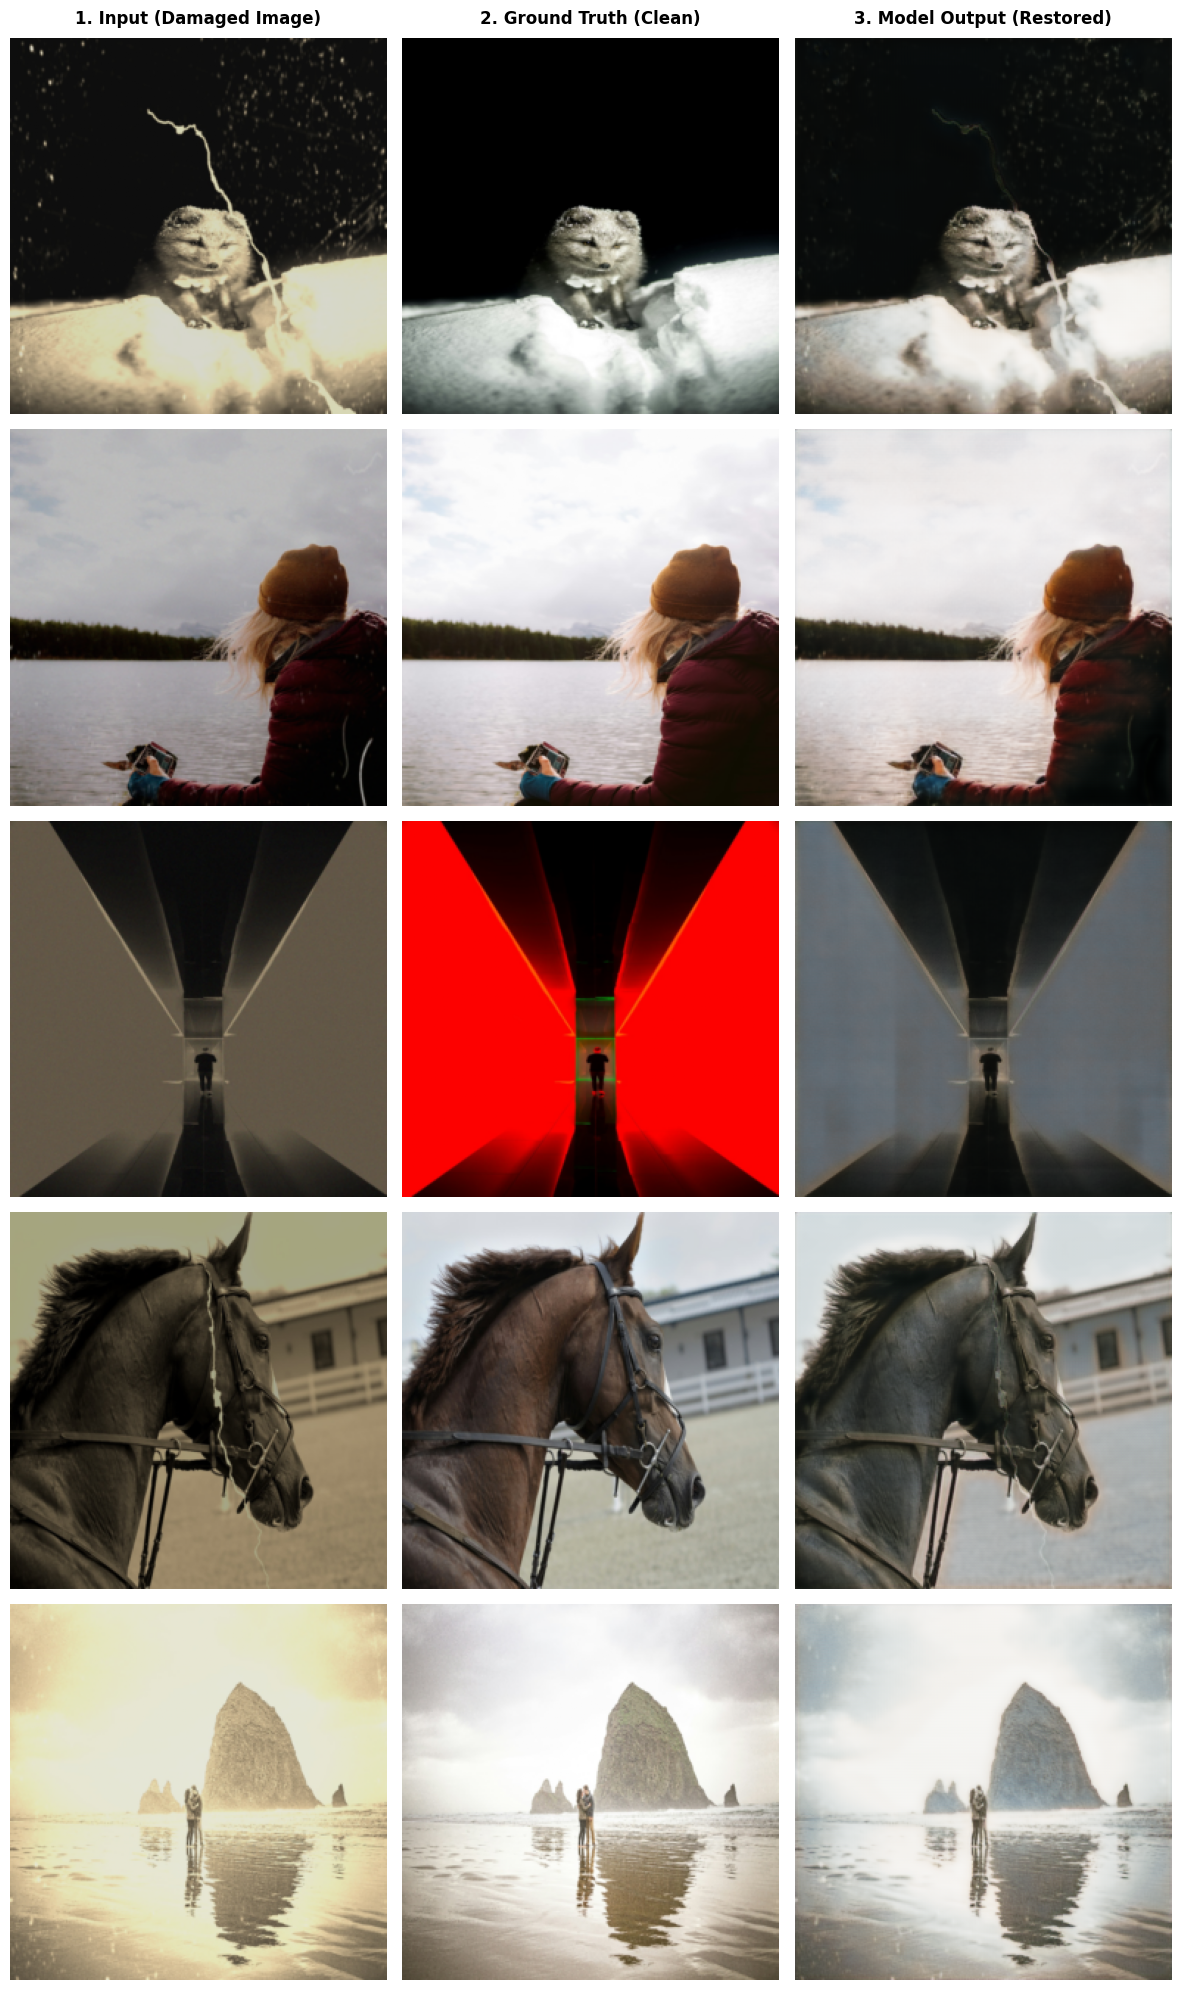

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()


data_iter = iter(test_loader)
damaged_batch, clean_batch = next(data_iter)

with torch.no_grad():
    damaged_batch = damaged_batch.to(device)
    reconstructed_batch = model(damaged_batch)

damaged_batch = damaged_batch.cpu()
reconstructed_batch = reconstructed_batch.cpu()


num_samples = 5
fig, axes = plt.subplots(nrows=num_samples, ncols=3, figsize=(12, 4 * num_samples))

axes[0, 0].set_title("1. Input (Damaged Image)", fontsize=12, fontweight='bold', pad=10)
axes[0, 1].set_title("2. Ground Truth (Clean)", fontsize=12, fontweight='bold', pad=10)
axes[0, 2].set_title("3. Model Output (Restored)", fontsize=12, fontweight='bold', pad=10)

for i in range(num_samples):
    img_input = np.clip(damaged_batch[i].numpy().transpose(1, 2, 0), 0, 1)
    img_truth = np.clip(clean_batch[i].numpy().transpose(1, 2, 0), 0, 1)
    img_recon = np.clip(reconstructed_batch[i].numpy().transpose(1, 2, 0), 0, 1)

    axes[i, 0].imshow(img_input)
    axes[i, 0].axis('off')  # Hide pixel coordinates grid
    axes[i, 0].set_ylabel(f"Sample {i+1}", fontsize=11, fontweight='bold') # Label rows

    axes[i, 1].imshow(img_truth)
    axes[i, 1].axis('off')

    axes[i, 2].imshow(img_recon)
    axes[i, 2].axis('off')


plt.tight_layout()
plt.show()

## Phase 6: Web UI Deployment (Gradio Studio)

For an interactive demonstration, we deploy the model via a web interface using **Gradio** (qualifying for the **10% bonus credit**).

### Features of the Web UI:
- **Modern Theme:** Built with Gradio's `Soft` layout using Slate and Blue highlights for a premium, clean aesthetic.
- **Drag-and-Drop Upload:** Users can drag, paste, or upload any corrupted photo.
- **Real-Time Inference:** When the submit button is clicked, the PIL image is resized to $256 \times 256$, normalized, passed through the model on the GPU/CPU, clipped to $[0.0, 1.0]$, upscaled back to $[0, 255]$ uint8, and returned for real-time visualization.


In [ ]:
import torch
import gradio as gr
from torchvision import transforms
from PIL import Image
import numpy as np


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Assuming 'model' is your trained UNet instance from the previous steps
model.to(device)
model.eval()


def enhance_image(input_pil_img):
    """
    Takes a PIL Image from the UI, pre-processes it, passes it through the
    U-Net model, and returns a PIL Image to display on the UI.
    """
    if input_pil_img is None:
        return None

    preprocess = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor()
    ])

    input_tensor = preprocess(input_pil_img.convert("RGB")).unsqueeze(0).to(device)

    with torch.no_grad():
        output_tensor = model(input_tensor)

    output_tensor = output_tensor.squeeze(0).cpu()

    output_np = torch.clamp(output_tensor, 0.0, 1.0).numpy().transpose(1, 2, 0)
    output_np = (output_np * 255).astype(np.uint8)

    return Image.fromarray(output_np)


custom_theme = gr.themes.Soft(
    primary_hue="blue",
    secondary_hue="slate",
)

with gr.Blocks(theme=custom_theme, title="Image Enhancement Studio") as demo:
    gr.Markdown(
        """
        # 📸 AI Image Restoration & Enhancement Studio
        ### Deep Learning Project - Powered by U-Net
        Upload a damaged, noisy, or corrupted photo below, and the trained deep-learning model will reconstruct it in real-time.
        """
    )

    with gr.Row():
        with gr.Column():
            input_ui = gr.Image(type="pil", label="1. Upload Damaged Image")
            submit_btn = gr.Button("✨ Restore & Enhance Image", variant="primary")

        with gr.Column():
            output_ui = gr.Image(type="pil", label="2. Reconstructed Model Output")

    submit_btn.click(
        fn=enhance_image,
        inputs=input_ui,
        outputs=output_ui
    )

    gr.Markdown(
        """
        ---
        *Note: The system automatically resizes incoming images to **256x256 pixels** and normalizes them to match the structure defined during the Model Training phase.*
        """
    )

demo.launch(share=True)

/tmp/ipykernel_718/1455694545.py:59: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(theme=custom_theme, title="Image Enhancement Studio") as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2591f1367dc9f2ccad.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 🏁 Summary, Limitations & Recommendations

### Identified Limitations:
1. **Softened High-Frequency Details:** The pixel-wise L1 loss averages fine details, leading to slightly blurry textures (e.g. hair, grass).
2. **Resolution Constraints:** The system is restricted to $256 \times 256$ inputs due to GPU memory and training speed limitations.
3. **Minor Color Desaturation:** In regions with severe damage, restored colors can occasionally drift towards desaturated or grey tones.

### Recommendations for Future Improvements:
1. **Perceptual Loss (VGG Feature Distance):** Incorporating a perceptual loss (using a pre-trained network like VGG19) forces the network to minimize difference in high-level feature spaces, greatly improving texture sharpness.
2. **Adversarial Training (GAN / Pix2Pix):** Introducing a Discriminator network to form a GAN structure (such as Pix2Pix) would encourage the generator to output realistic, sharp textures to fool the discriminator, solving the blurriness issue.
3. **Attention Mechanisms:** Integrating Channel Attention (e.g., Squeeze-and-Excitation blocks) or Self-Attention layers in the bottleneck will help the network focus computing capacity on damaged regions.
4. **Learning Rate Schedulers:** Using learning rate decay schedules (e.g., Cosine Annealing) to fine-tune weights during the final epochs.
